## 1) Introduction to Stochastic Gene Expression
## Gene expression involves various interactions
### - Transcription factors binding to promoter
### - RNA polymerase transcribing mRNA
### - Translation of mRNA into proteins

### The models we have used so far involve deterministic dynamics, where the interactions denoted above happen in exactly the way they are described. 
### These models tend to predict average behavior (mean field theorem), 
### however in small-scale systems (aka; gene expression!), randomness can have a significant effect
### Stochastic gene expression refers to the fact that these processes happen randomly at different times.

## Why Do We Need Stochastic Models?
### If the number of molecules involved is large, deterministic models work well eg; small random fluctuations in the number of bacteria in an ocean model 
### However, when molecule numbers are small - random fluctuations can drastically affect observed dynamics!
### A single gene turning ON or OFF can have large consequential effects eg; large variations in protein numbers between cells

### The main computational take away from the next 2 weeks of labs will be the Gillespie Algorithm.

### In short, the Gillespie Algorithm: 
#### 1) Determines when the next event will occur
#### 2) Chooses which event (e.g., production or degradation) will happen
#### 3) Updates the system state and repeats the process.

### BUT before diving into the algorithm itself, we first need to understand a key mathematical concept: 
### poisson processes and waiting times --> main part of todays lecture

## 2) Poisson Processes and Waiting Time Theory
### A Poisson process models events that occur randomly over time, such as mutations or molecule production/degradation
### In a Poisson process, events occur randomly over time with a fixed average rate.
### However, the exact time of the next event is unknown—it follows an exponential distribution
### This means that while we can calculate the average waiting time, the actual time fluctuates

## Example: 
### Let's say an event happens at a rate b (e.g., 5 times per hour)
### We want to know the probability that the next event occurs exactly at time t

### Logically this means:
#### 1) It should not happen before time t—meaning, in every tiny time step dt, the event does not occur
#### 2) It must occur at time t—meaning, in the tiny time step from t to t+dt, the event does occur

### Mathematically this means: 
#### - The probability that the event does not happen in a small time step dt is (1−bdt).
#### - If we divide time into many small intervals from 0 to t, the event must not occur in any of those intervals.
#### - The probability of this happening is approximately $e^{-bt}$ which decreases over time—this is why long waiting times are less likely.
#### - Finally, multiplying this by the probability that the event does occur at t, we get: $$p(t) = \overbrace{e^{-bt}}^{\text{prob of event not happening till t}} * \overbrace{b}^{\text{prob of event happening at t}}$$ $$ p(t) = be^{-bt}$$
### This is the exponential distribution, which tells us that short waiting times are more likely than long ones.
### This is the KEY result: A process that occurs at a rate b leads to exponentially distributed events
### This is termed a Poisson process --> one in which the average time between events is fixed, 
### but the exact time of the next event is unknown and sampled from a memory-less (exponential) distribution.

### Now it is time to generate exponentially distributed random numbers

In [6]:
import numpy as np
import matplotlib.pyplot as plt
b=3
np.random.exponential(1/b)
#Here, the rate is 3 per hr, and the function np.random.exponential takes a single input – the inverse of the rate
# and returns an exponentially distributed random number.

0.012629366692069885

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Exponentially distributed random numbers</b> 
    
***

Plot the probability distribution for 104
and 105
exponentially sampled random numbers. Are the realized distributions
in fact exponential? Now, change the rate parameter, e.g., setting it to b = 0.2, 0.5, 2 or 3. Recall that the hist
command is one way to visualize distributions, although there are other options as well. If your code works, the result
should look something like the following:
</div>


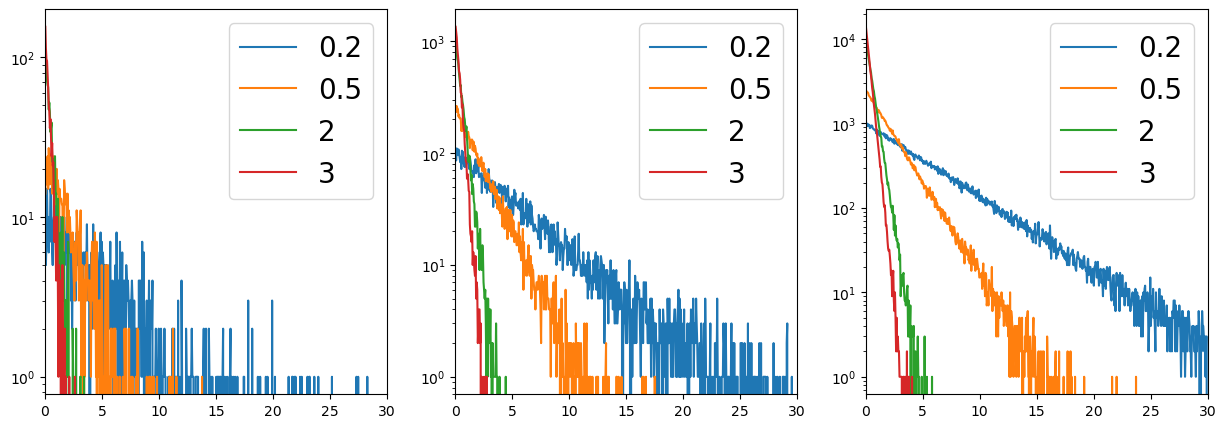

In [8]:
import numpy as np
import matplotlib.pyplot as plt
row,col=(1,3)
fig,ax=plt.subplots(row,col,figsize=(col*5,row*5))
nums=[10**3,10**4,10**5]
bs=[0.2,0.5,2,3]
bi=np.arange(0,30.05,0.05)

for num in range(len(nums)):
    n=nums[num]
    for b in bs:
        d=np.random.exponential(1/b,n)
        ns, bin_edges=np.histogram(d,bins=bi)
        bin_mids=(bin_edges[1:] + bin_edges[:-1])/2
        ax[num].plot(bin_mids,ns)
    ax[num].set_yscale('log')
    ax[num].set_xlim(0,30)
    ax[num].legend([z for z in bs],fontsize=20)


### The code generates random samples of sizes $10^3,10^4, \text{and }10^5$ to analyze their probability distribution functions (PDFs). 
### It visualizes the distributions using histograms with logarithmically scaled y-axes, revealing their exponential nature. 
### The slopes of the plotted lines represent the rate parameter (b)
### which is close to but not exactly the generating value.
### However, the 95% confidence intervals (CIs) are expected to include the true mean.


## Understanding Bootstrapping for Estimating Confidence Intervals
#### In simulations or experiments, we often want to estimate parameters (e.g., the average time between events or the rate of a process) and quantify the uncertainty in our estimates. 
#### One way to do this is by bootstrapping, a statistical method that uses random resampling to approximate the confidence interval (CI) of an estimate.
### Now work through the bootstrapping/confidence interval part on your own - not much to teach here!

In [11]:
num=10**5
bvals=[.2,.5,2,3]
b_est=np.zeros(len(bvals))
b_ci=np.zeros((len(bvals),2))
#loop for b
for i in range(len(bvals)):
    b=bvals[i]
    x=np.random.exponential(1/b,num)
    #mean
    b_est[i]=1/np.mean(x)
    tmpn=1000
    bootstrap_est=np.zeros(tmpn)
    for j in range(tmpn):
        #sample from x, allow repeats
        tmpind=np.random.randint(num,size=num)
        bootstrap_x=x[tmpind]
        bootstrap_est[j]=1/np.mean(bootstrap_x)
    bootstraps_sorted=np.sort(bootstrap_est)
    b_ci[i,0]=bootstraps_sorted[int(tmpn*0.025)]
    b_ci[i,1]=bootstraps_sorted[int(tmpn*0.975)]
b_ci

array([[0.19900408, 0.20137454],
       [0.49650684, 0.50233221],
       [1.99001446, 2.01365304],
       [2.97723954, 3.01478291]])

## 3) Multiple Stochastic Events
### Now we know how to calculate our waiting times for the next Poisson event to happen 
### But.. what if there are multiple events in the same system? How do we calculate our waiting time to the next event
### And also.. which event happens first?
### Specifically, what if we have two competing events:

#### - Protein production at rate $b_1$
#### - Protein degradation at rate $b_2$


In [13]:
# Set rates
b1 = 0.5   # Protein production rate
b2 = 2.5   # Protein degradation rate

# Generate random waiting times for each event
r1 = np.random.exponential(1/b1)
r2 = np.random.exponential(1/b2)

# The event that happens first
next_event_time = min(r1, r2)

print(f"The next event occurs at time {next_event_time:.3f} hours")


The next event occurs at time 1.207 hours


### Intuitively try doing this part on your own, 
### understand why you will mostly get your next event happen closer to a certain value (use a for loop as suggested in the text)

In [15]:
# Generate a random number between 0 and 1

for i in range(15):
    # Determine which event occurs
    U = np.random.rand()
    if U < (b1 / (b1 + b2)):
        event = "Protein Production"
    else:
        event = "Protein Degradation"
    
    print(f"The first event is: {event}")

The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Production
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Production
The first event is: Protein Degradation
The first event is: Protein Degradation
The first event is: Protein Degradation


### Now that we understand how multiple stochastic events are timed, 
### we can compare our simulated results with the theoretical expectation. 
### We can once again say that the waiting time until the first event happens follows an exponential distribution $p(t) = e^{-bt}$
### But importantly this time with a rate $b = b_1 + b_2$
### Where the probability that event 1 happens first is $\frac{b_1}{b_1+b_2}$ and the probability that event 2 happens first is $\frac{b_2}{b_1+b_2}$

### We should see this pattern in our simulation.
### A useful way to analyze and compare distributions is through the Cumulative Distribution Function (CDF).

### Cumulative Distribution Function (CDF) gives the probability that an event occurs by a certain time t, 
### rather than at an exact time (aka at or before a certain time t)

### Mathematically, the CDF for an exponential distribution with rate is $$Q(t) = 1-e^{-bt}$$
### This function tells us how likely it is that the event has already happened by time t 

### Eg; If Q(1)=0.7, this means there is a 70% chance that an event has already occurred before t=1

### As t increases, Q(t) approaches 1 (event certainty)

### How Do We Compare the CDF of Simulated Data?
#### 1) Run many simulations of the event process and record the waiting times.
#### 2) Sort the waiting times and calculate how many events occurred before each time (this gives the empirical CDF).
#### 3) Plot both the empirical CDF and the theoretical CDF for comparison.

### We will now generate 1000 simulations, extract the waiting times, 
### and compare the empirical distribution to the theoretical expectation.

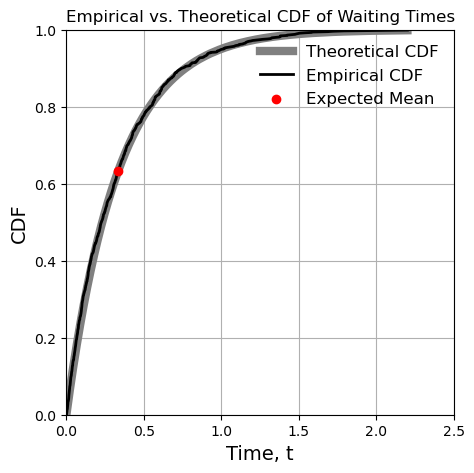

In [20]:
# Define event rates
b1 = 0.5   # Protein production rate
b2 = 2.5   # Protein degradation rate
n = 1000   # Number of simulations

# Generate waiting times for both events
x1 = np.random.exponential(1/b1, n)
x2 = np.random.exponential(1/b2, n)

# Find the time of the first event in each simulation
etime = np.minimum(x1, x2)  # Element-wise min operation

# Sort event times to build the empirical CDF
sortdata = np.sort(etime)
cdfvals = np.arange(n) / n  # Fraction of values less than each sorted value

# Define the theoretical CDF for an exponential process with rate b1 + b2 
# remember lambda is just a short form function that takes 1 parameter 
poiss3cdf = lambda t: 1 - np.exp(-(b1 + b2) * t)

# Plot the empirical CDF vs. theoretical expectation
plt.figure(figsize=(5,5))
plt.plot(sortdata, poiss3cdf(sortdata), color='gray', linewidth=6, label="Theoretical CDF")
plt.plot(sortdata, cdfvals, color='k', linewidth=2, label="Empirical CDF")
plt.scatter(1/(b1+b2), poiss3cdf(1/(b1+b2)), color='red', label="Expected Mean", zorder=3)

plt.xlabel("Time, t", fontsize=14)
plt.ylabel("CDF", fontsize=14)
plt.legend(fontsize=12, frameon=False, loc="upper right")
plt.xlim(0, 2.5)
plt.ylim(0, 1)
plt.grid(True)
plt.title("Empirical vs. Theoretical CDF of Waiting Times")
plt.show()


### The gray curve represents the theoretical CDF based on $b = b_1 + b_2 = 3$ per hour 
### The black curve represents the empirical CDF from 1000 simulated waiting times given the two events and their rates
### The red dot marks the expected mean waiting time $1/(b_1+b_2)$, showing where the average event should occur.

## Conclusions:
### - The empirical CDF closely follows the theoretical CDF, confirming that our simulation follows the expected Poisson process.
### - The average event time is shorter than for either process alone, since multiple competing events increase the likelihood of something happening sooner.
### - This confirms that rates of events add together, and the timing of the first event follows an exponential distribution with rate

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Identity of Random Events</b> 
    
***

This challenge is centered on solving the following: given two independent Poisson processes operating concurrently,
what fraction of times do each of the two processes take place first? That is to say, if b1 = 0.5 and b2 = 2.5, what
fraction of events are associated with process 1 and what fraction of events are associated with process 2? Write your
own code to try and solve this, leveraging the code already written thus far in the laboratory guide.
</div>

In [24]:
# Generate random numbers
num=10**3
b1=0.5
b2=2.5
b1_rnd=np.random.exponential(1/b1,num)
b2_rnd=np.random.exponential(1/b2,num)
# Find out which came first
tmpi1=np.argwhere(b1_rnd<b2_rnd)
tmpi2=np.argwhere(b2_rnd<=b1_rnd)
print('Fraction of 1-events that come first is',len(tmpi1)/num)
print('Fraction of 2-events that come first is',len(tmpi2)/num)

Fraction of 1-events that come first is 0.161
Fraction of 2-events that come first is 0.839


### Takeaways: if $b_1 = 0.5$ and $b_2 = 2.5$, event 1 occurs first $b_1/(b_1 + b_2)$ = 1/6th of the time and event 2 occurs 5/6th of the time

### The simulation confirms the theoretical expectation—the fraction of times each event occurs first matches their relative rates

## Key Takeaways
### - Instead of always picking the shortest waiting time,
###  - we can first determine when any event will occur using a Poisson process with a total rate equal to the sum of all individual event rates.
### - After determining the time of the next event, we select which specific event happens based on their relative probabilities.
### - Events with higher rates are more likely to occur first.
### - This method is the core principle of the Gillespie Algorithm, allowing efficient and accurate simulation of stochastic biochemical and cellular processes

In [28]:
#### Lesson Split

# Introduction to the Gillespie Algorithm in Gene Expression
### The Gillespie Algorithm is a widely used method for simulating stochastic processes in biology and chemistry. 
### In gene expression, molecules like mRNA and proteins are produced and degraded at random times, making deterministic models inaccurate for small molecule numbers.

### Instead of assuming continuous changes, the Gillespie Algorithm models individual events step by step, considering:
### 1) When the next event occurs.
### 2) Which event happens (e.g., production or degradation).
### 3) How the system updates after the event

### Our work last week gave us very pretty steady states eg; $p^* = \beta/\alpha$
### However how realistic is this? Can we really have "decimal place" protein levels? What is there is random fluctuation in production?

## According to the Gillespie algorithm, the total rate at which any event occurs is the sum of the rates of individual processes:
## Our individual process are production $\beta$ and decay $\alpha p$
## Plotting these two processes as a function of p gives us an intersection, can someone tell me what this value intuitively is?


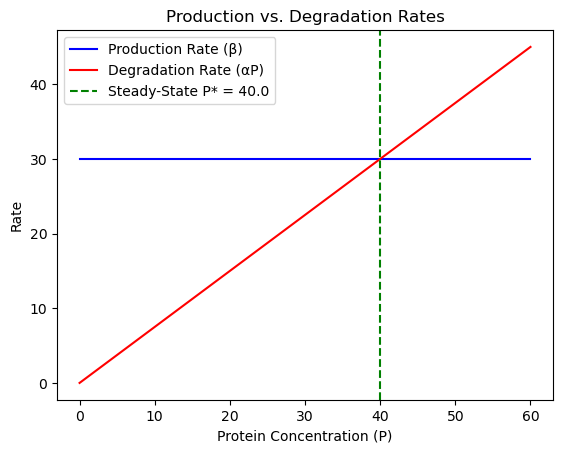

In [33]:

beta = 30  # Production rate
alpha = 0.75  # Degradation rate
P_vals = np.linspace(0, 60, 100)  # Protein concentration values


production_rate = np.full_like(P_vals, beta)  # Constant beta
degradation_rate = alpha * P_vals  # Linear degradation


plt.plot(P_vals, production_rate, label="Production Rate (β)", linestyle="-", color="blue")
plt.plot(P_vals, degradation_rate, label="Degradation Rate (αP)", linestyle="-", color="red")


P_star = beta / alpha
plt.axvline(P_star, color="green", linestyle="dashed", label=f"Steady-State P* = {P_star}")


plt.xlabel("Protein Concentration (P)")
plt.ylabel("Rate")
plt.title("Production vs. Degradation Rates")
plt.legend()
plt.show()


<div class="alert alert-block alert-warning">
<b>Challenge Problem:  State-Dependent Rates</b> 
    
***

Write code that calculates the probability of decay as a function of the state p. Using this code, calculate the probability
of decay at equilibrium, i.e., when $p^* =\beta / \alpha = 30/1$ . 

Use code and visualizations to support your argument. If your code
is working, it should look like this, depending on whether you visualize from 0 to 60 proteins (left) or from 0 to 300
(right):
</div>

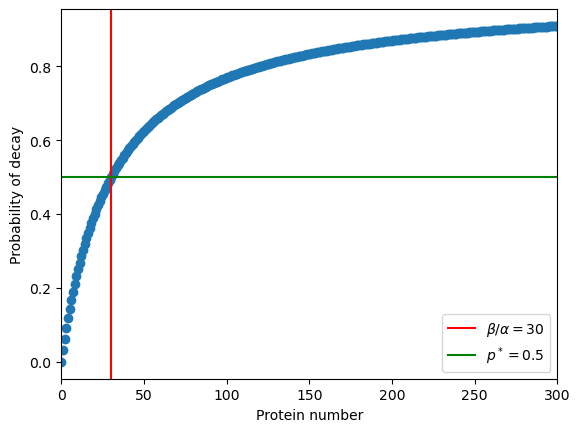

In [36]:
alpha = 1
r = 30
probdecay = lambda p: alpha*p/(r+alpha*p)
# Plot the probability of decay as a function of proteins
pvec = np.linspace(0,300,300)
plt.scatter(pvec,probdecay(pvec))
plt.xlim(0,300)
plt.xlabel('Protein number')
plt.ylabel('Probability of decay')
plt.axvline(30, label = r'$\beta / \alpha = 30$', color = 'red')
plt.axhline(0.5, label = r'$p^* = 0.5$', color = 'green')
plt.legend()

### The probability of a decay event taking place before a production event is the ratio of the decay rate to the total rate of all processes.
### Hence, it is $αp/(β + αp)$ -> which is a saturating function of p. 
### Note that at equilibrium then $β = αp^∗$ such that by definition, the probability of decay is 1/2, the probability of production is 1/2, 
### and so the system is equally likely to increase protein levels by 1 as it is to decrease protein levels by 1

 # How the Gillespie Algorithm Works with  Gene Expression
 ## Step-by-Step Breakdown (read alongside pseudocode and try coding up)
 
 ### 1) Initialize the system: set time range and set initial values of t= 0, P = 0
 
 ### 2) Compute event rates: 
 #### - Production rate: $\beta$
 #### - Degradation rate: $\alpha P$
 
 ### 3) Determine the waiting time until the next event
 #### - Draw a random waiting time from an exponential distribution with rate $\beta$ +  $\alpha P$ (recall that we add the rates if we are waiting for next event)
 
 ### 4) Determine which event occurs 
 #### - Calculate the probability of production or degradation eg; P(prod) =  $\frac{\beta}{\beta +  \alpha P}$
 #### - Randomly decide if production or degradation occurs  
 
 ### 5) Apply event and update state accordingingly
 
 ### 6) Store updated state 
 
 ### 7) Repeat steps 2-6 in a loop till you reach your time limit
 
## Now follow the pages in the booklet, and plot your gillespie algorithms to reproduce figure right above bonus
### Note: save the gillespie algorithm as a FUNCTION (booklet doesn't do that)

Text(0, 0.5, 'Protein p(t)')

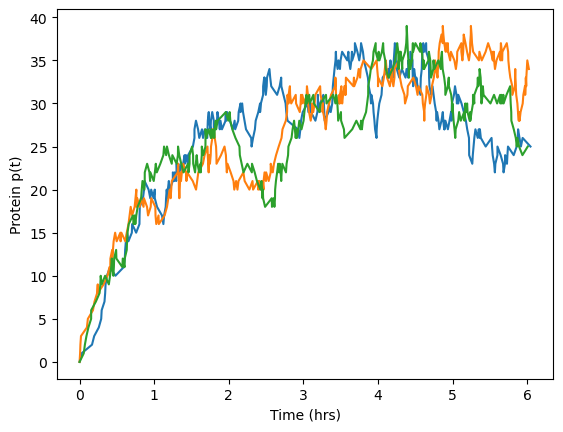

In [68]:
# Define the stochastic simulation function with a time range
def stochsim_protein(trange, p0, beta, alpha):
    currp = p0  # Initial protein count
    currt = trange[0]  # Start time
    tvals = [currt]
    pvals = [currp]

    while currt < trange[1]:  # Use trange instead of tmax
        # Calculate rates
        decayrate = alpha * currp
        prodrate = beta
        total_rate = decayrate + prodrate
        
        # Find waiting time
        deltat = np.random.exponential(1 / total_rate)
        currt += deltat   
        prob_produce = prodrate / total_rate

        # Update state
        if np.random.uniform() < prob_produce:
            currp += 1
        else:
            currp -= 1
            
        # Record state
        tvals.append(currt)
        pvals.append(currp)

    return np.array(tvals), np.array(pvals)

# Set parameters
tmax = 6
p0 = 0
alpha = 1
beta = 30



# Run the simulation 3 times with range-based time input
for i in range(3):
    t, p = stochsim_protein([0, tmax], p0, beta, alpha)  # Use time range [0, tmax]
    plt.plot(t, p)
plt.xlabel('Time (hrs)')
plt.ylabel('Protein p(t)')

## Takeaways: 
### - This function accurately simulates gene expression using the Gillespie Algorithm
### - The random nature of the process leads to different protein levels in each simulation
### - While random, the steady-state protein count fluctuates around  $p^* = \beta/\alpha = 30$  but individual trajectories vary due to stochastic effects.


## On your own, try out the new variations they talk about - note that the differences and explore the system!

# Sampling of Stochastic Trajectories
### - Stochastic trajectories are hard to compare because events happen at random intervals instead of fixed time points
### - Experimental data is collected at regular intervals, making direct comparison b/w experiments and stochastic trajectories challenging
### - Resampling stochastic trajectories at fixed times helps align them with experimental measurements
### - This ensures better consistency and comparability across different simulations

## Steps to Sample a Stochastic Trajectory at Fixed Times (read alongside pseudocode and try coding up)
### 1) Define a vector of fixed time points for sampling.
### 2) Create an empty vector to store sampled protein counts.
### 3) Loop through each fixed time point and find the most recent protein count before that time.
### 4) Store this value in the sampled dataset.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Discrete sampling of stochastic trajectories</b> 
    
***

Implement a function to take the output of an event-driven Gillespie algorithm and return the values of the state
at discrete or otherwise pre-specified intervals. This will be useful in moving from the system perspective to the
measurement perspective – see Figure 2.
(right):
</div>

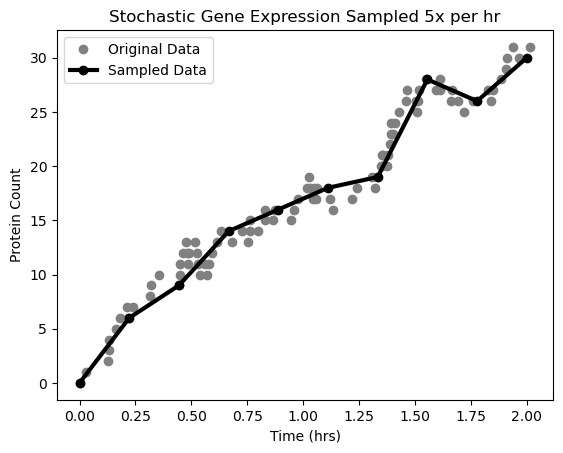

In [44]:


# Function to sample a trajectory at discrete time intervals
def sample_traj(t, y, trange):
    
    """ Samples a trajectory (t, y) at discrete intervals in trange """
    
    t = np.array(t)
    y = np.array(y)
    
    # Initialize arrays using np.zeros
    ts = np.zeros(np.shape(trange)) # Time points we want to sample at
    ys = np.zeros(np.shape(trange))# Protein values at sampled times

    # Initialize first sampled point
    curt = trange[0]
    ind = np.argwhere(t <= curt)
    curind = ind[-1][0]  # Extract valid index
    ts[0] = t[curind]
    ys[0] = y[curind]

#Scans across the sample interval and then moves the actual dynamics forward until we cross it
    for i in range(1, len(trange)):
        nextt = trange[i]
        while curind < len(t) and t[curind] < nextt:
            curind += 1
        ts[i] = nextt
        ys[i] = y[curind - 1]  # Take the last valid y-value

    return ts, ys

# Set parameters
alpha = 1
beta = 30
tmax = 2
p0 = 0
interval = 0.2 #sampled every interval

# Run the Gillespie algorithm (now using `stochsim`)
t, y = stochsim_protein([0, tmax], p0, beta, alpha)

# Plot the original trajectory
plt.plot(t, y, 'o', color='grey', label="Original Data")

# Sample the trajectory according to interval set
ts, ys = sample_traj(t, y, np.linspace(0, tmax, int(tmax / interval)))

# Plot the sampled trajectory
plt.plot(ts, ys, 'ko-', linewidth=3, label="Sampled Data")

# Add labels and legend
plt.xlabel("Time (hrs)")
plt.ylabel("Protein Count")
plt.title("Stochastic Gene Expression Sampled " + str(round(1/interval)) + "x per hr")
plt.legend()
plt.show()


### What the sampling function does:
### 1) Takes arrays t (time) and y (protein levels) that we get from our Gillespie algorithm
### 2) Initialize ts (sampled time points) and ys (sampled protein levels) as zero arrays of the same size as trange.
### 3) Finds the first recorded protein value before the first sampling time.
### 4) Loop through all sampling times:
#### - Find the most recent protein count before or at each sampling time.
#### - Store the corresponding protein count.
### 5) Return the sampled time and protein arrays.

# Steady State Analysis

### Now that we have a working Gillespie algorithm and a method to sample stochastic trajectories (yay!)
### the next challenge is to analyze and compare steady-state statistics in two ways:
### 1) Tracking a Single Long-Term Simulation:

#### - Run the Gillespie algorithm for 20 hours starting with 0 proteins.
#### - Use the final protein count as the initial condition for a new simulation.
#### - Run the second simulation for 100 more hours.
#### - Sample 1000 time points between 20 and 120 hours (i.e., every 6 minutes).
#### - Compute the mean and variance of the protein count over time.
#### - Analyze the distribution of protein numbers across time.

### 2) Tracking Many Independent Simulations:

#### - Run 1000 separate 20-hour simulations, each starting with 0 proteins.
#### - Record the final protein count of each simulation.
#### - Compute the mean, variance, and distribution of final protein numbers across these runs.

### This is the crux of the next challenge problem! 
#### Note that challenge problem asks for poisson distribution points as well, that is a bonus (def try, but important is to show across time vs across trajectories)

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Steady State Distributions of Stochastic Gene Expression
</b> 
    
***

Develop code that compares and contrasts the output of the long-term sampling of a single trajectory vs. sampling of
many trajectories at distinct points. Use β = 30, α = 1, and sample at the 20 hr point across 1000 runs or sample
every 0.1 hrs after reaching the 20 hr point. If your code works it should look like:
(below):
</div>

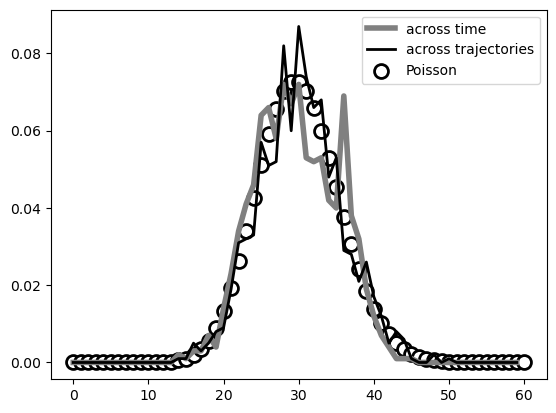

In [51]:
import scipy.stats as stats
# Parameters
beta = 30
alpha = 1

# Long term trajectory
t, y = stochsim_protein([0,20],0,beta,alpha)
y0 = y[-1]
t, y = stochsim_protein([0,100],y0,beta,alpha)
trange = np.linspace(0,100,1001)
ts, ys = sample_traj(t,y,trange)

# Histogram
py,px = np.histogram(ys,np.arange(0,61))
plt.plot(px[:-1],py/sum(py),linewidth=4,color=[0.5,0.5,0.5], label = 'across time' )

# Simulate many trajectories
numsamps = 1001
final_y0 = np.zeros(numsamps)
for j in range(numsamps):
    t, y = stochsim_protein([0,20],0,beta,alpha)
    final_y0[j] = y[-1]
    
py2,px2 = np.histogram(final_y0,np.arange(0,61))
plt.plot(px2[:-1],py2/sum(py2),linewidth=2,color='k', label = 'across trajectories' )

# Calculate the distribution in theory
px_theory = np.arange(0,61)
py_theory = stats.poisson.pmf(px_theory,beta/alpha)
plt.scatter(px_theory,py_theory,c='w',edgecolors='k',s=100,linewidth=2, label = 'Poisson' )

plt.legend()

### Bonus: Why Does This Lead to a Poisson Distribution?

### A Poisson distribution describes the probability of observing a certain number of events in a fixed time, given a constant average rate.

### For stochastic gene expression:
#### - The system reaches a steady state when production and degradation balance out on average
#### - At steady state, the number of proteins  P fluctuates, but its probability follows the equation $$ P(P = k) = \frac{e^{-\lambda} \lambda^k}{k!}$$
#### Where $\lambda = \frac{\beta}{\alpha}$ is the mean steady-state protein count

#### This means that, over time, the probability of finding a given number of proteins follows a Poisson distribution centered around $\lambda = \frac{\beta}{\alpha}$